## Import libraries

In [16]:
# Imports necessary to execute the code
from pathlib import Path
from careamics_portfolio import PortfolioManager
import matplotlib.pyplot as plt
import numpy as np
import tifffile
import random
import shutil

## Import the dataset

The dataset can be directly downloaded using the `careamics-portfolio` package, which
uses `pooch` to download the data.

The CARE U2OS dataset is composed of thousands of examples organized in train and test:

- train
    - low: low SNR data
    - GT: high SNR data
- test
    - low: low SNR data
    - GT: high SNR data
 


In [2]:
# instantiate data portfolio manage
portfolio = PortfolioManager()

In [3]:
print(portfolio)

Portfolio:
Denoising datasets: ['N2N_SEM', 'N2V_BSD68', 'N2V_SEM', 'N2V_RGB', 'Flywing', 'Convallaria', 'CARE_U2OS', 'Tribolium']
DenoiSeg datasets: ['DSB2018_n0', 'DSB2018_n10', 'DSB2018_n20', 'Flywing_n0', 'Flywing_n10', 'Flywing_n20', 'MouseNuclei_n0', 'MouseNuclei_n10', 'MouseNuclei_n20']


In [4]:
portfolio.denoising.Flywing.description

'Image of a membrane-labeled fly wing (35x692x520 pixels).'

In [13]:
# # and download the data
data_dir = Path("../data_careamics")
# download = portfolio.denoising.CARE_U2OS.download(root_path)
# download = portfolio.denoising.Convallaria.download(root_path)
# download = portfolio.denoiseg.MouseNuclei_n20.download(root_path)

# path to the training data
root = data_dir / "denoising-CARE_U2OS.unzip" / "data" / "U2OS"
# train_path = root_path / "train" / "low"
# target_path = root_path / "train" / "GT"

### Collect matching images and annotations

In [9]:
# Match each image to its same-named mask across both source splits.
source_pairs = []
# seen_image_names = set()

for split_name in ("train", "test"):
    input_dir = root / split_name / "low"
    output_dir = root / split_name / "GT"
    if not input_dir.is_dir() or not output_dir.is_dir():
        raise FileNotFoundError(f"Expected input/ and output/ folders under {root / split_name}")

    image_files = sorted(input_dir.glob("*.tif"))
    if not image_files:
        raise FileNotFoundError(f"No .tif images found in {input_dir}")

    for image_path in image_files:
        mask_path = output_dir / image_path.name
        if not mask_path.is_file():
            raise FileNotFoundError(f"No matching annotation for {image_path}")
        # if image_path.name in seen_image_names:
        #     raise ValueError(f"Duplicate image filename across source splits: {image_path.name}")
        # seen_image_names.add(image_path.name)
        source_pairs.append((image_path, mask_path))

print(f"Collected {len(source_pairs)} matched image-mask pairs from the source splits")

Collected 3072 matched image-mask pairs from the source splits


## Make a reproducible 80/10/10 split

Set `N_IMAGES` to the number of image-mask pairs to sample. It must be a positive multiple of 10 so the train, test, and validation sets remain exactly 80%, 10%, and 10%. `SPLIT_SEED` controls which pairs are selected and keeps the split reproducible. Each image is copied as TIFF, and its annotation is read from TIFF and saved as a NumPy `.npy` array named `<image>_masks.npy` in the same split folder. The original source files are unchanged. Training images are also copied without masks to `A172_manual_training` next to the generated split folder.

In [19]:
N_IMAGES = 50
SPLIT_SEED = 42

if N_IMAGES <= 0 or N_IMAGES % 10 != 0:
    raise ValueError("N_IMAGES must be a positive multiple of 10 for an exact 80/10/10 split")
if N_IMAGES > len(source_pairs):
    raise ValueError(f"Requested {N_IMAGES} pairs, but only {len(source_pairs)} are available")

selected_pairs = random.Random(SPLIT_SEED).sample(source_pairs, N_IMAGES)
n_train = N_IMAGES * 8 // 10
n_test = N_IMAGES // 10

train_pairs = selected_pairs[:n_train]
test_pairs = selected_pairs[n_train:n_train + n_test]
validation_pairs = selected_pairs[n_train + n_test:]

assert len(train_pairs) == n_train
assert len(test_pairs) == N_IMAGES // 10
assert len(validation_pairs) == N_IMAGES // 10

# Use a separate output root so the original A172/train and A172/test remain untouched.
prepared_dir = data_dir / f"U2OS_splits_n{N_IMAGES}_seed{SPLIT_SEED}"
split_groups = {
    "train": train_pairs,
    "test": test_pairs,
    "validation": validation_pairs,
}

for split_name, pairs in split_groups.items():
    split_dir = prepared_dir / split_name
    split_dir.mkdir(parents=True, exist_ok=True)
    copied_pairs = []
    for image_path, mask_path in pairs:
        split_image = split_dir / image_path.name
        split_mask = split_dir / f"{image_path.stem}_seg.npy"
        shutil.copy2(image_path, split_image)
        mask_array = tifffile.imread(str(mask_path)).squeeze().astype(np.uint16)
        # otlines must be also added to the dictionary otherwise cellpose does not read the mask.
        # outlines = mask_array * utils.masks_to_outlines(mask_array)
        if mask_array.ndim != 2 or not np.issubdtype(mask_array.dtype, np.integer):
            raise ValueError(f"Expected a 2D integer-label annotation: {mask_path}")
        # print(f'"split_mask": {split_mask}, "filename": {str(image_path)}')
        np.save(split_mask, {"masks": mask_array, "outlines": outlines, "filename": str(image_path)})
        copied_pairs.append((split_image, split_mask))
    split_groups[split_name] = copied_pairs

manual_training_dir = data_dir / prepared_dir / f"manual_training_n{N_IMAGES}_seed{SPLIT_SEED}"
manual_training_dir.mkdir(parents=True, exist_ok=True)
for split_image, _ in split_groups["train"]:
    shutil.copy2(split_image, manual_training_dir / split_image.name)

train_pairs = split_groups["train"]
test_pairs = split_groups["test"]
validation_pairs = split_groups["validation"]

assert len(train_pairs) == n_train
assert len(test_pairs) == N_IMAGES // 10
assert len(validation_pairs) == N_IMAGES // 10
print(f"Copied {len(train_pairs)} train, {len(test_pairs)} test, and {len(validation_pairs)} validation pairs to {prepared_dir}")
print(f"Copied {len(split_groups['train'])} training images without masks to {manual_training_dir}")

NameError: name 'outlines' is not defined

## Visualize data

Text(0.5, 1.0, 'Target image')

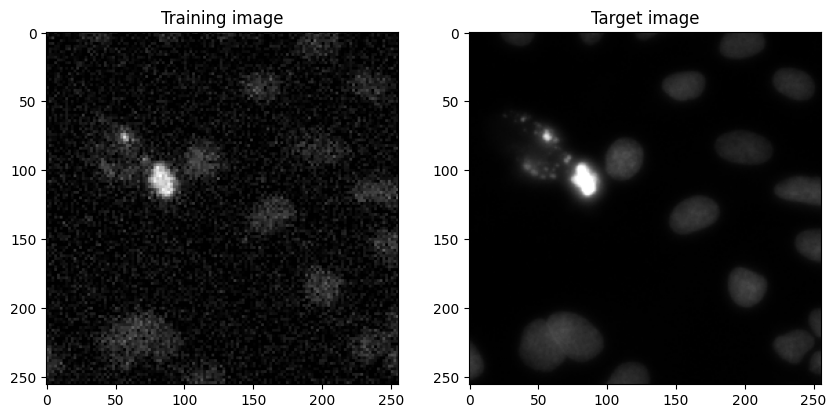

In [27]:
# load training image and target, and show them side by side
train_files = list(train_path.rglob("*.tif"))
train_files.sort()

target_files = list(target_path.rglob("*.tif"))
target_files.sort()

# select random example
ind = np.random.randint(len(train_files))
train_image = tifffile.imread(train_files[ind])
train_target = tifffile.imread(target_files[ind])

# plot the two images and a crop
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(train_image, cmap="gray")
ax[00].set_title("Training image")

ax[1].imshow(train_target, cmap="gray")
ax[1].set_title("Target image")